<a href="https://colab.research.google.com/github/packageIncoming/MAT422/blob/main/MAT422_Section_3_7_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mert Isik
Fall 2026


# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical formulation, Activation functions, Cost function, Backpropagation, Backpropagation algorithm

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [20]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)


## Mathematical formulation

This section gives one compact Python demonstration of **Mathematical formulation**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [21]:
X = np.array([[0,1], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 3))
b1 = np.zeros((1, 3))
W2 = rng.normal(scale=0.5, size=(3, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)


Hidden layer values:
[[-0.69724 -0.11969  0.44297]
 [-0.69724 -0.11969  0.44297]
 [ 0.76367  0.25701  0.32008]
 [ 0.14209  0.14167  0.6683 ]]
Initial predicted probabilities:
[[0.58828]
 [0.58828]
 [0.41711]
 [0.49511]]


This section shows how a neural network is formed. A neural network is essentially various layers of matrix multiplication that is wrapped up with a final function at each layer.

## Activation functions

This section gives one compact Python demonstration of **Activation functions**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


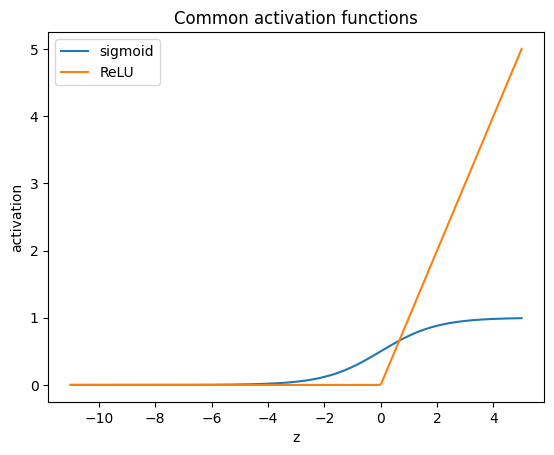

In [22]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-11, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()


Activation functions are the functions applied at the end of each layer. Two commonly used functions, sigmoid and ReLU, are shown in the picture above.

## Cost function

This section gives one compact Python demonstration of **Cost function**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [23]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())


Initial binary cross-entropy = 0.7439463574521953
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.58828 0.58828 0.41711 0.49511]


The cost function describes how wrong the neural network is and is a key part of training since it gives the training process a goal, namely to minimize cost function.

## Backpropagation

This section gives one compact Python demonstration of **Backpropagation**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [24]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")


dW2 shape: (3, 1)
db2 shape: (1, 1)
dW1 shape: (2, 3)
db1 shape: (1, 3)
Backpropagation sends the output error backward through W2 and the tanh derivative.


Back propagation is part of "fixing" the neural network after figuring out how wrong the NN was on an input. It is the process of applying the chain rule backwards through neurons, adjusting them based on how much of an impact they had on the final result.

## Backpropagation algorithm

This section gives one compact Python demonstration of **Backpropagation algorithm**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


Final probabilities:
[[0.49921]
 [0.49921]
 [0.99734]
 [0.00434]]
Final predictions: [0 0 1 0]


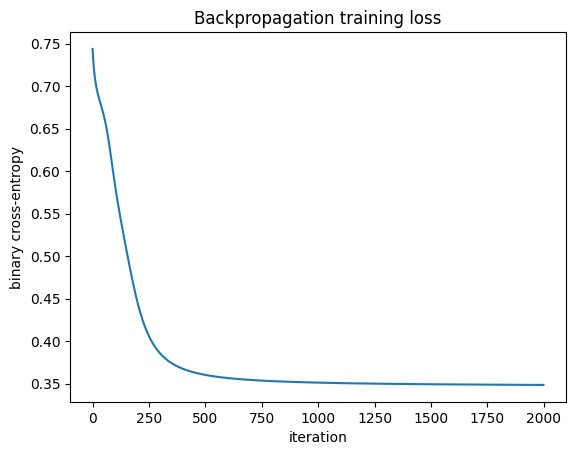

In [25]:
learning_rate = 0.2
losses = []
for step in range(2000):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)
print("Final probabilities:")
print(final_output)
print("Final predictions:", (final_output > 0.5).astype(int).ravel())

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()


This section shows the entire learning process put together, in a loop where we run inputs, calculate the cost, then run backpropagation to fix the neurons.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
